# TEsseract ocr - OPENCV

In [43]:
!pip install opencv-python
!pip install pytesseract
#!sudo apt-get install tesseract-ocr

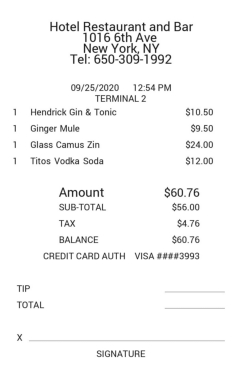

In [44]:
import cv2
import urllib
import pytesseract
import matplotlib.pyplot as plt

url = "https://github.com/ezponda/intro_deep_learning/blob/main/images/restaurant-bar-receipt-sample.jpg?raw=true"
urllib.request.urlretrieve(url, "restaurant-bar-receipt-sample.jpg")

# Path to the image
image_path = "restaurant-bar-receipt-sample.jpg"
# Load an image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

plt.imshow(image, cmap='gray')
plt.axis('off')
plt.show()

In [45]:
text = pytesseract.image_to_string(image) # con tesseract podemos pasarlo a texto!
print(text)

Hotel Restaurant and Bar
6th Ave
New York, NY
Tel: 650-309-1992

09/25/2020 12:54PM

TERMINAL 2
Hendrick Gin & Tonic $10.50
Ginger Mule $9.50
Glass Camus Zin $24.00
Titos Vodka Soda $12.00
Amount $60.76
SUB-TOTAL $56.00
TAX $4.76
BALANCE $60.76

CREDIT CARD AUTH VISA ####3993

TIP
TOTAL

 

SIGNATURE



In [46]:
!tesseract --help-psm
# para usar esto siempre lo metemos en el parmetro de configuracion entonces se tiene que poner dentro de ..psm y leugo poner la confituacion que se quiere.

Page segmentation modes:
  0    Orientation and script detection (OSD) only.
  1    Automatic page segmentation with OSD.
  2    Automatic page segmentation, but no OSD, or OCR. (not implemented)
  3    Fully automatic page segmentation, but no OSD. (Default)
  4    Assume a single column of text of variable sizes.
  5    Assume a single uniform block of vertically aligned text.
  6    Assume a single uniform block of text.
  7    Treat the image as a single text line.
  8    Treat the image as a single word.
  9    Treat the image as a single word in a circle.
 10    Treat the image as a single character.
 11    Sparse text. Find as much text as possible in no particular order.
 12    Sparse text with OSD.
 13    Raw line. Treat the image as a single text line,
       bypassing hacks that are Tesseract-specific.


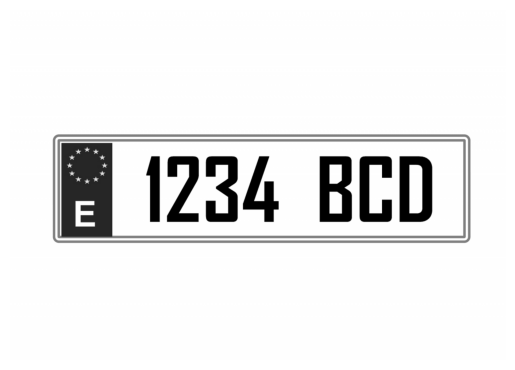

In [47]:
url = 'https://github.com/ezponda/intro_deep_learning/blob/main/images/car_plate.png?raw=true'
urllib.request.urlretrieve(url, "car_plate.png")


image_1 = cv2.imread("car_plate.png", cv2.IMREAD_GRAYSCALE)

plt.imshow(image_1, cmap='gray')
plt.axis('off')
plt.show()

In [48]:
text = pytesseract.image_to_string(image_1) # si lo ejecutamos sin ponerle ningun tipod e configuracion con el que leer la imagen vemos que nos da un texto vacio
print(text)

In [49]:
config = '--psm 11' # el mejor para la imagen de la matricula es la opcion 11
config2 = '--psm 11 -l eng' # se le puede configurar el idioma en q leerlo tmb

text = pytesseract.image_to_string(image_1, config=config2)
print(text)

1234 BCD



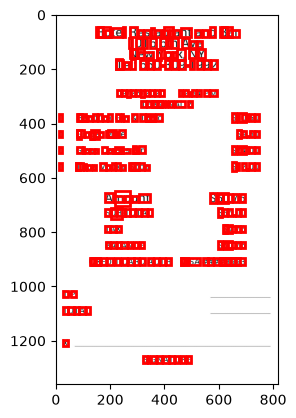

In [50]:
from matplotlib import patches


# Use pytesseract to detect characters and their boxes
config = '--psm 6 -l eng'
boxes = pytesseract.image_to_boxes(image, config=config)

# Plotting the image and boxes
fig, ax = plt.subplots(1)
ax.imshow(image, cmap='gray')

# Adding the boxes to the image
for b in boxes.splitlines():
    b = b.split(' ')
    ax.add_patch(patches.Rectangle((int(b[1]), image.shape[0] - int(b[2])), int(b[3]) - int(b[1]), int(b[2]) - int(b[4]), fill=False, edgecolor='red', lw=2))

#plt.axis('off')
plt.show() # usando image to boxes, nos devuelve las cajas donde estan situacio cada texto. cada caja es un caracter y nos indica las coordenadas de las cajas

In [51]:
print(boxes)

H 149 1281 174 1315 0
o 154 1281 199 1317 0
t 180 1281 202 1306 0
e 205 1281 243 1312 0
l 248 1281 253 1317 0
R 272 1281 297 1315 0
e 301 1281 322 1306 0
s 326 1281 346 1306 0
t 349 1281 362 1312 0
a 366 1281 387 1306 0
u 393 1281 413 1306 0
r 397 1281 433 1315 0
a 420 1281 433 1306 0
n 435 1281 456 1306 0
t 461 1281 499 1312 0
a 514 1281 535 1306 0
n 541 1281 562 1306 0
d 566 1281 587 1317 0
B 606 1281 629 1315 0
a 613 1281 649 1315 0
r 634 1281 674 1306 0
1 270 1241 282 1275 0
0 295 1241 316 1275 0
1 322 1241 334 1275 0
6 347 1241 369 1275 0
6 385 1241 407 1275 0
t 409 1241 422 1272 0
h 427 1241 448 1277 0
A 463 1241 492 1275 0
v 494 1241 516 1266 0
e 518 1241 539 1266 0
N 272 1201 297 1235 0
e 280 1201 323 1235 0
w 303 1201 359 1226 0
Y 373 1195 389 1237 0
o 373 1201 400 1235 0
r 403 1201 425 1226 0
k 431 1201 444 1226 0
, 447 1195 475 1237 0
N 492 1201 517 1235 0
Y 523 1201 550 1235 0
T 222 1161 245 1197 0
e 222 1161 248 1195 0
l 250 1161 271 1186 0
: 277 1161 293 1197 0
6 311 1161

In [52]:
import pandas as pd
config = '--psm 6 -l eng'
data = pytesseract.image_to_data(image,config=config, output_type=pytesseract.Output.DICT)
print(data.keys())
df = pd.DataFrame(data)
df.head(10) # con esto nos da un listado de lo que nos da cada uno de los caracteres y se peude ver todo en un df

dict_keys(['level', 'page_num', 'block_num', 'par_num', 'line_num', 'word_num', 'left', 'top', 'width', 'height', 'conf', 'text'])


,level,page_num,block_num,par_num,line_num,word_num,left,top,width,height,conf,text
0,1,1,0,0,0,0,0,0,819,1361,-1,
1,2,1,1,0,0,0,13,44,734,1236,-1,
2,3,1,1,1,0,0,13,44,734,1236,-1,
3,4,1,1,1,1,0,149,44,525,36,-1,
4,5,1,1,1,1,1,149,44,104,36,96,Hotel
5,5,1,1,1,1,2,272,46,227,34,96,Restaurant
6,5,1,1,1,1,3,514,44,73,36,96,and
7,5,1,1,1,1,4,606,46,68,34,95,Bar
8,4,1,1,1,2,0,270,84,269,36,-1,
9,5,1,1,1,2,1,270,86,99,34,96,1016


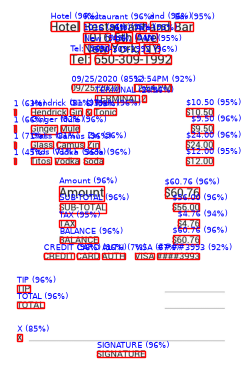

In [53]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.imshow(image, cmap='gray')
plt.axis('off')

# Iterate over each word
for i in range(len(df)):
    # Only consider entries with a confidence level
    if df['conf'][i] > 0:
        # Extract coordinates and dimensions of the bounding box
        (x, y, w, h) = (df['left'][i], df['top'][i], df['width'][i], df['height'][i])
        plt.gca().add_patch(Rectangle((x, y), w, h, fill=False, edgecolor='red', lw=1))
        text = f"{df['text'][i]} ({df['conf'][i]}%)"
        plt.gca().text(x, y - 10, text, color='blue', fontsize=6)

plt.show()

In [55]:
next = False
amount = ''
for i, row in df.iterrows():
    if next == True:
        amount = row['text']
        next = False
    line_num = row['line_num']
    word_num = row['word_num']
    text = row['text']
    if text == 'Amount':
        next = True
    # print(line_num, word_num, text)

print(amount)

$60.76


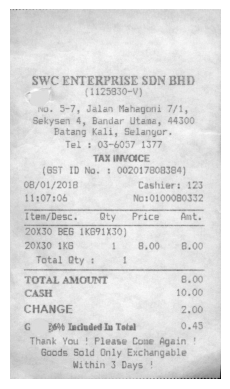

In [ ]:
# preprocesamiento de imagenes para enchangin ocr quality:
# aunque sea peor calidad tmb los pilla bien la vd aunque hay algunos errores por ello hay que usar técnicas
url = 'https://github.com/ezponda/intro_deep_learning/blob/main/images/bad_quality_receipt.png?raw=true'
urllib.request.urlretrieve(url, "bad_quality_receipt.png")

image_bad = cv2.imread('bad_quality_receipt.png', cv2.IMREAD_GRAYSCALE)

plt.imshow(image_bad, cmap='gray')
plt.axis('off')
plt.show()

In [57]:
config = '--psm 6 -l eng'

text = pytesseract.image_to_string(image_bad, config=config)
print(text)

SWC ENTERPRISE SDN BHD
ay (1125850-V)}
no. 5-7, Jalan Mahagoni 7/1,
Sekysen 4, Bandar Utama, 44300
Batang Kali, Selangor.
Tel : 03-6057 1377 |
TAX INVOICE
(GST ID No. : 002017808384)
06/01/2018 Cashier: 123
11:07:06 No:0100080332
Item/Desc. Qty Price Amt.
2OX30 BEG 1KG91X30)
20X30 1KG i 8.00 8.00
Total Qty : i
TOTAL AMOUNT 8.00
CASH 10.00
CHANGE 2,00
G 86% Incladed In Totel 0.45
Thank You ! Please Come Again !
Goods Sold Only Exchangable
Within 3 Days | i :



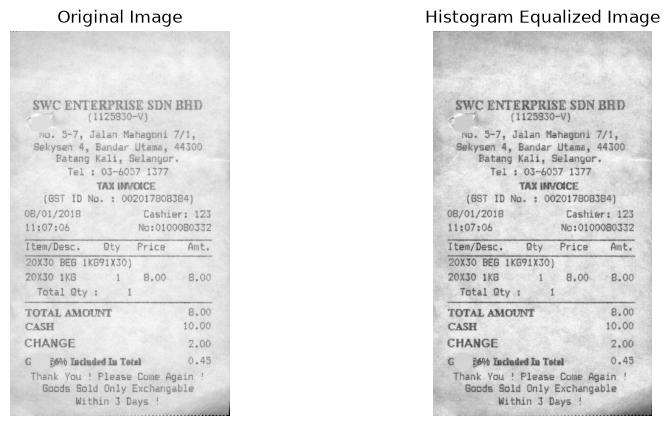

In [ ]:
#equalizamos la imagen con la funcion que usamos antes
import cv2
import matplotlib.pyplot as plt

def equalize_histogram(gray_image):
    clahe = cv2.createCLAHE(clipLimit=1.0, tileGridSize=(8, 8))
    return clahe.apply(gray_image)


equalized_image = equalize_histogram(image_bad)

# Display both images
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_bad, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(equalized_image, cmap='gray')
plt.title('Histogram Equalized Image')
plt.axis('off')

plt.show()
# parece que asi el tecto se ve bastante mejor

In [59]:
import cv2
import pytesseract
from ipywidgets import interact, IntSlider, FloatSlider
from IPython.display import HTML, display

def apply_clahe(clipLimit, tileGridSize):
    # Ensure the image is in BGR format
    if len(image_bad.shape) == 2 or image_bad.shape[2] == 1:  # Image is already grayscale
        gray_image = image_bad
    else:
        gray_image = cv2.cvtColor(image_bad, cv2.COLOR_BGR2GRAY)
    
    # Create a CLAHE object
    clahe = cv2.createCLAHE(clipLimit=clipLimit, tileGridSize=(tileGridSize, tileGridSize))
    
    # Apply CLAHE to the grayscale image
    clahe_image = clahe.apply(gray_image)
    
    # Display the results
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(gray_image, cmap='gray')
    plt.title('Original Grayscale Image')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(clahe_image, cmap='gray')
    plt.title('CLAHE Enhanced Image')
    plt.axis('off')
    
    plt.show()
    
    # Perform OCR on the CLAHE-enhanced image
    config = '--psm 6 -l eng'
    text = pytesseract.image_to_string(clahe_image, config=config)
    # Print the OCR results in a "cooler" text box
    #print("\033[1;32;40m OCR Result: \n{}\033[0m".format(text))
    print("OCR Result: \n{}".format(text))


# Interactive widget for CLAHE parameters
interact(apply_clahe, 
         clipLimit=FloatSlider(min=0, max=5, step=0.1, value=2, description='Clip Limit'),
         tileGridSize=IntSlider(min=1, max=32, step=1, value=8, description='Tile Grid Size'))

# tmb podemos jugar un poco con estos valores para ver como se veria mejor

interactive(children=(FloatSlider(value=2.0, description='Clip Limit', max=5.0), IntSlider(value=8, descriptio…

<function __main__.apply_clahe(clipLimit, tileGridSize)>

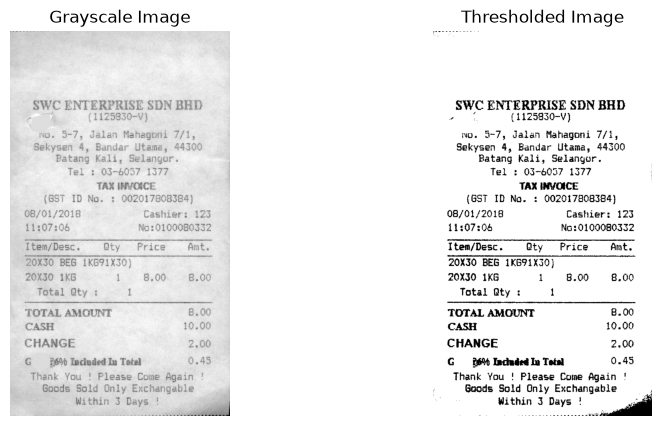

In [ ]:
# con thresholding:
def apply_thresholding(image):
    return cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

# Apply thresholding
thresh_image = apply_thresholding(image_bad)

# Display images
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_bad, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(thresh_image, cmap='gray')
plt.title('Thresholded Image')
plt.axis('off')

plt.show()
# aqui parece que se ve mejor... con las letras mas en claro pero igual empeora cosas

In [ ]:
config = '--psm 6 -l eng'

text = pytesseract.image_to_string(thresh_image, config=config)
print(text) # con esto como se puede ver acierta bastante bien

SWC ENTERPRISE SDN BHD
- 4 (1125950-V)
ng. +7, Jalan Mahagoni 7/1,
Sekysen 4, Bandar Utama, 44300
Ratang Kali, Selangor. |
Tel : 03-6057 1377 ,
TAX INVOICE
(GST ID No. : 002017808384)
08/01/2018 Cashier: 123
11:07:06 No 20100080332
Item/Desc. Qty Price Amt.
20X30 BEG 1KG91X50}
20X30 1KG 1 8.00 8.00
Total Qty : 1
TOTAL AMOUNT 8.00
CASH 10.00
CHANGE 2.00
G 26% Included In Toisl 0.45
Thank You ! Please Come Again !
: Gaods Sold Only Exchangable
Within 3 Days ! “a :



In [ ]:
from ipywidgets import interact, widgets


def interactive_ocr_preprocessing(clipLimit, tileGridSize, thresh_type, threshold, block_size, C):
    # Ensure the image is in BGR format
    if len(image_bad.shape) == 2 or image_bad.shape[2] == 1:  # Image is already grayscale
        gray_image = image_bad
    else:
        gray_image = cv2.cvtColor(image_bad, cv2.COLOR_BGR2GRAY)
    
    # Apply CLAHE to the grayscale image, if selected
    if clipLimit > 0 and tileGridSize > 0:
        clahe = cv2.createCLAHE(clipLimit=clipLimit, tileGridSize=(tileGridSize, tileGridSize))
        processed_image = clahe.apply(gray_image)
    else:
        processed_image = gray_image

    # Apply thresholding based on the user's choice
    if thresh_type == 'Binary':
        _, processed_image = cv2.threshold(processed_image, threshold, 255, cv2.THRESH_BINARY)
    elif thresh_type == 'Adaptive Mean':
        processed_image = cv2.adaptiveThreshold(processed_image, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, block_size, C)
    elif thresh_type == 'Adaptive Gaussian':
        processed_image = cv2.adaptiveThreshold(processed_image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, block_size, C)
    
    # Display the processed image
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(gray_image, cmap='gray')
    plt.title('Original Grayscale Image')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.imshow(processed_image, cmap='gray')
    plt.title('Processed Image')
    plt.axis('off')
    
    plt.show()
    
    # Perform OCR on the processed image
    config = '--psm 6 -l eng'
    text = pytesseract.image_to_string(processed_image, config=config)
    # Print the OCR results in a styled format
    print("OCR Result: \n{}".format(text))

interact(interactive_ocr_preprocessing, 
         clipLimit=widgets.FloatSlider(min=-1, max=5, step=0.1, value=0, description='CLAHE CL', continuous_update=False),
         tileGridSize=widgets.IntSlider(min=0, max=16, step=1, value=0, description='CLAHE Grid-Size', continuous_update=False),
         thresh_type=widgets.Dropdown(options=['None', 'Binary', 'Adaptive Mean', 'Adaptive Gaussian'], value='None', description='Threshold Type'),
         threshold=widgets.IntSlider(min=0, max=255, step=1, value=127, description='Binary Th', continuous_update=False),
         block_size=widgets.IntSlider(min=3, max=21, step=1, value=11, description='Adpt Block Size', continuous_update=False, disabled=False),
         C=widgets.IntSlider(min=0, max=20, step=1, value=2, description='Adpt C Value', continuous_update=False)
        );

# como se puede ver aqui podemos jugar bastante con los distintos valores como hemos hecho previamente

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='CLAHE CL', max=5.0, min=-1.…

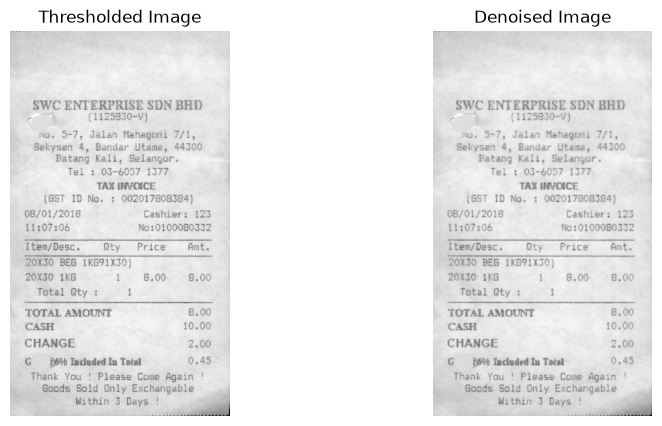

In [ ]:
# quitando sonido:
def remove_noise(image):
    return cv2.medianBlur(image, 3)

# Apply noise removal
denoised_image = remove_noise(image_bad)

# Display images
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_bad, cmap='gray')
plt.title('Thresholded Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(denoised_image, cmap='gray')
plt.title('Denoised Image')
plt.axis('off')

plt.show()
# como vemos no se aprecia mucho al diferencia e incluso se ve peor

In [64]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
# This code creates a 5x5 rectangular structuring element.
print(kernel)

[[1 1 1]
 [1 1 1]
 [1 1 1]]


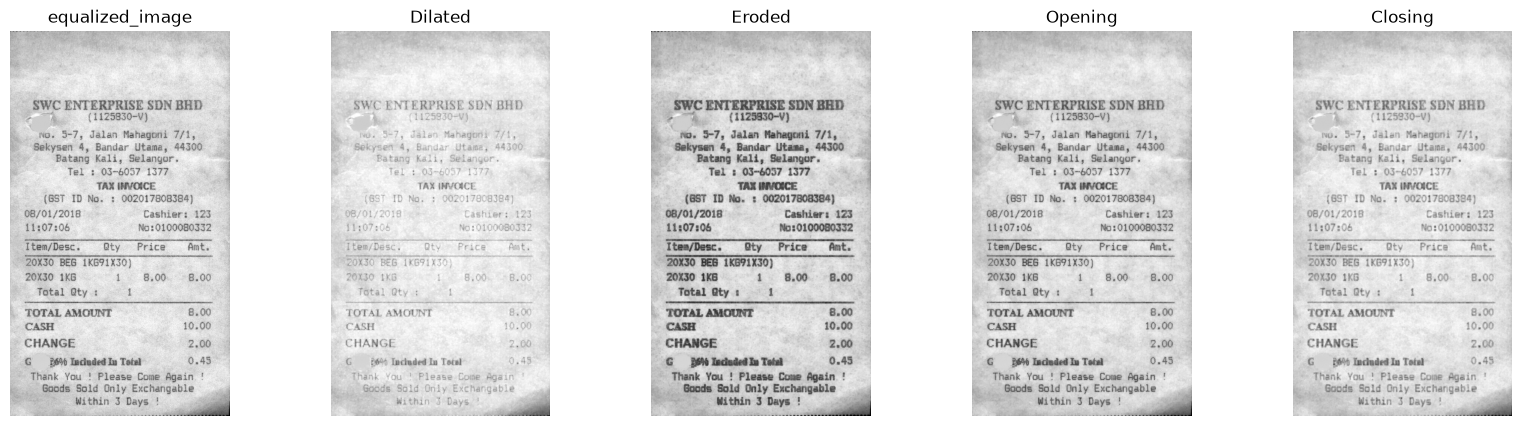

In [65]:
# Apply dilation
dilated_image = cv2.dilate(equalized_image, kernel, iterations=1)

# Apply erosion
eroded_image = cv2.erode(equalized_image, kernel, iterations=1)

# Apply opening
opening_image = cv2.morphologyEx(equalized_image, cv2.MORPH_OPEN, kernel)

# Apply closing
closing_image = cv2.morphologyEx(equalized_image, cv2.MORPH_CLOSE, kernel)

# Plotting the images
fig, axs = plt.subplots(1, 5, figsize=(20, 5))
axs[0].imshow(equalized_image, cmap='gray')
axs[0].set_title('equalized_image')
axs[1].imshow(dilated_image, cmap='gray')
axs[1].set_title('Dilated')
axs[2].imshow(eroded_image, cmap='gray')
axs[2].set_title('Eroded')
axs[3].imshow(opening_image, cmap='gray')
axs[3].set_title('Opening')
axs[4].imshow(closing_image, cmap='gray')
axs[4].set_title('Closing')

for ax in axs:
    ax.axis('off')
plt.show()

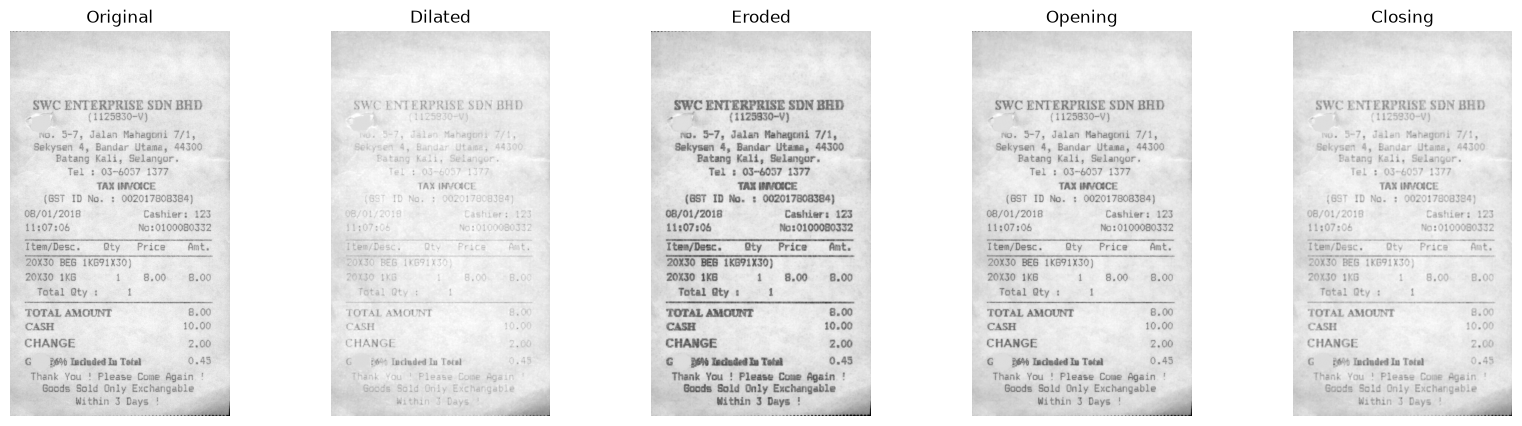

In [66]:
# Apply dilation
dilated_image = cv2.dilate(image_bad, kernel, iterations=1)

# Apply erosion
eroded_image = cv2.erode(image_bad, kernel, iterations=1)

# Apply opening
opening_image = cv2.morphologyEx(image_bad, cv2.MORPH_OPEN, kernel)

# Apply closing
closing_image = cv2.morphologyEx(image_bad, cv2.MORPH_CLOSE, kernel)

# Plotting the images
fig, axs = plt.subplots(1, 5, figsize=(20, 5))
axs[0].imshow(image_bad, cmap='gray')
axs[0].set_title('Original')
axs[1].imshow(dilated_image, cmap='gray')
axs[1].set_title('Dilated')
axs[2].imshow(eroded_image, cmap='gray')
axs[2].set_title('Eroded')
axs[3].imshow(opening_image, cmap='gray')
axs[3].set_title('Opening')
axs[4].imshow(closing_image, cmap='gray')
axs[4].set_title('Closing')

for ax in axs:
    ax.axis('off')
plt.show()